In [1]:

!pip install gTTS -q

from gtts import gTTS
import subprocess
import os
from IPython.display import Audio, display
import wave
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

text = "Are you going to the party tonight?"
tts = gTTS(text, lang='en')
tts.save("temp.mp3")
subprocess.run(['ffmpeg', '-y', '-i', 'temp.mp3', '-ar', '8000', '-ac', '1', '-c:a', 'pcm_s16le', 'speech.wav'], capture_output=True)

CompletedProcess(args=['ffmpeg', '-y', '-i', 'temp.mp3', '-ar', '8000', '-ac', '1', '-c:a', 'pcm_s16le', 'speech.wav'], returncode=0, stdout=b'', stderr=b"ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers\n  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)\n  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-l

--- Audio Info (read by wave module) ---
Sample Rate: 8000 Hz
Channels: 1
Total Samples: 20736
Audio Length: 2.59 seconds

Playing original audio:


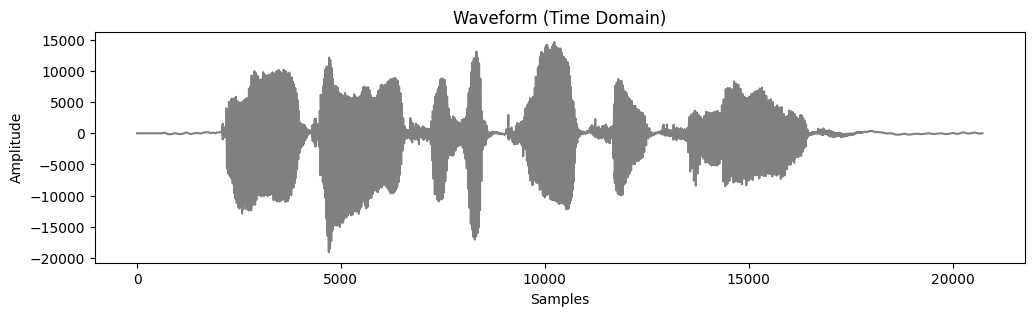

--- Slicing Info ---
25ms window size = 200 samples
10ms step size = 80 samples

Slicing complete! Audio divided into 257 windows.


In [2]:


filename = "speech.wav"
with wave.open(filename, 'rb') as wav_file:
    sample_rate = wav_file.getframerate()
    num_channels = wav_file.getnchannels()
    num_frames = wav_file.getnframes()
    sampwidth = wav_file.getsampwidth()

    raw_data = wav_file.readframes(num_frames)

if sampwidth == 2:
    data = np.frombuffer(raw_data, dtype=np.int16)
elif sampwidth == 1:
    data = np.frombuffer(raw_data, dtype=np.uint8)
else:
    data = np.frombuffer(raw_data, dtype=np.int32)

if num_channels > 1:
    data = data.reshape(-1, num_channels)
    data = data[:, 0]

print("--- Audio Info (read by wave module) ---")
print(f"Sample Rate: {sample_rate} Hz")
print(f"Channels: {num_channels}")
print(f"Total Samples: {len(data)}")
print(f"Audio Length: {len(data) / sample_rate:.2f} seconds\n")

print("Playing original audio:")
display(Audio(data, rate=sample_rate))

plt.figure(figsize=(12, 3))
plt.plot(data, color='gray')
plt.title("Waveform (Time Domain)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

window_ms = 25
step_ms = 10

window_size = int((window_ms / 1000) * sample_rate)
step_size = int((step_ms / 1000) * sample_rate)

print("--- Slicing Info ---")
print(f"25ms window size = {window_size} samples")
print(f"10ms step size = {step_size} samples")

frames = []

for i in range(0, len(data) - window_size, step_size):
    frame = data[i : i + window_size]
    frames.append(frame)

print(f"\nSlicing complete! Audio divided into {len(frames)} windows.")

In [3]:

spectrogram_data = []
energy_data = []

for frame in frames:
    frame_float = frame.astype(np.float32)

    energy = np.sum(frame_float ** 2)
    energy_data.append(energy)

    fft_result = np.fft.rfft(frame_float)
    magnitude = np.abs(fft_result)

    log_magnitude = 10 * np.log10((magnitude ** 2) + 1e-10)
    spectrogram_data.append(log_magnitude)

spectrogram_matrix = np.array(spectrogram_data).T

max_freq_bins = spectrogram_matrix.shape[0]
energy_array = np.array(energy_data)
energy_normalized = (energy_array / np.max(energy_array)) * (max_freq_bins * 0.8)


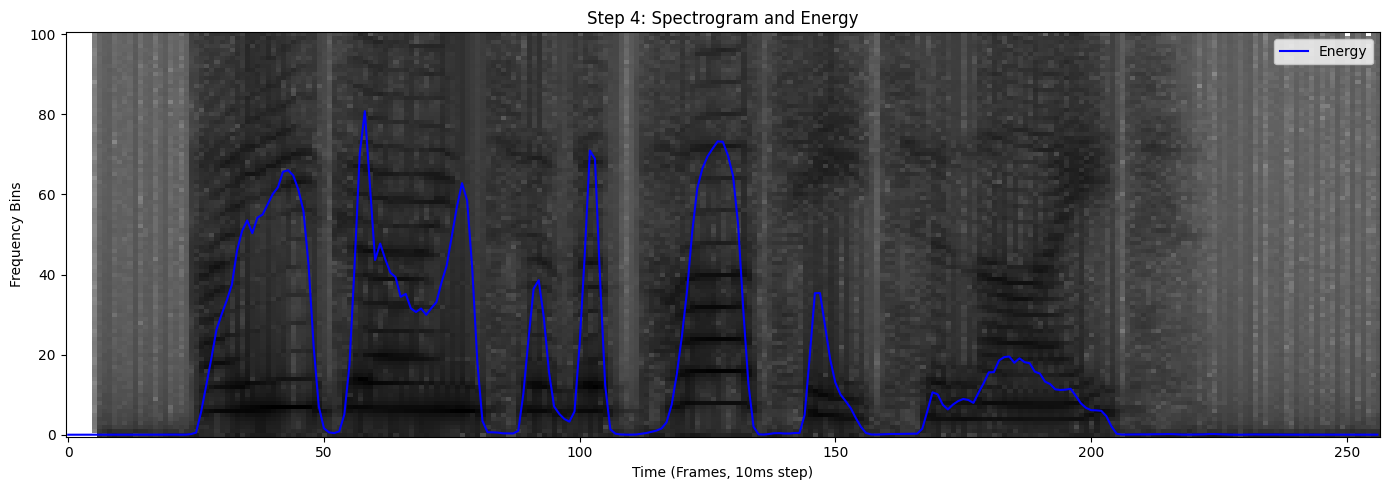

In [4]:


plt.figure(figsize=(14, 5))

plt.imshow(spectrogram_matrix, aspect='auto', origin='lower', cmap='gray_r')

plt.plot(energy_normalized, color='blue', linewidth=1.5, label='Energy')

plt.title("Step 4: Spectrogram and Energy")
plt.xlabel("Time (Frames, 10ms step)")
plt.ylabel("Frequency Bins")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

✅ Step 5 calculation complete! Drawing spectrogram with pitch (red dots)...


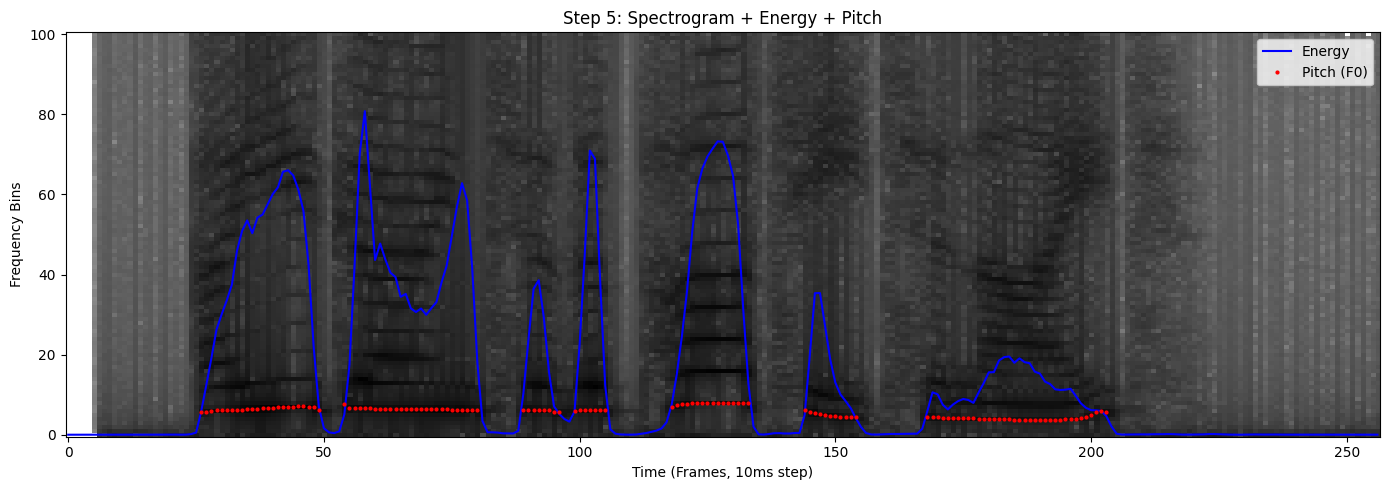

In [5]:

pitch_data_hz = []
pitch_bins = []

min_pitch = 75
max_pitch = 500
min_lag = int(sample_rate / max_pitch)
max_lag = int(sample_rate / min_pitch)

energy_threshold = np.max(energy_data) * 0.05

for i, frame in enumerate(frames):
    frame_float = frame.astype(np.float32)

    if energy_data[i] < energy_threshold:
        pitch_data_hz.append(0)
        pitch_bins.append(np.nan)
    else:
        correlation = np.correlate(frame_float, frame_float, mode='full')
        correlation = correlation[len(correlation)//2:]
        valid_corr = correlation[min_lag:max_lag]

        if len(valid_corr) > 0:
            peak_idx = np.argmax(valid_corr)
            true_lag = peak_idx + min_lag
            pitch_hz = sample_rate / true_lag
            pitch_data_hz.append(pitch_hz)

            bin_idx = pitch_hz * (window_size / sample_rate)
            pitch_bins.append(bin_idx)
        else:
            pitch_data_hz.append(0)
            pitch_bins.append(np.nan)

print("✅ Step 5 calculation complete! Drawing spectrogram with pitch (red dots)...")

plt.figure(figsize=(14, 5))
plt.imshow(spectrogram_matrix, aspect='auto', origin='lower', cmap='gray_r')
plt.plot(energy_normalized, color='blue', linewidth=1.5, label='Energy')
plt.plot(pitch_bins, color='red', marker='.', markersize=4, linestyle='none', label='Pitch (F0)')

plt.title("Step 5: Spectrogram + Energy + Pitch")
plt.xlabel("Time (Frames, 10ms step)")
plt.ylabel("Frequency Bins")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

👉 Feature detected! Possibly a question (pitch rises from 153.8Hz to 228.6Hz).

✅ Drawing final complete chart...


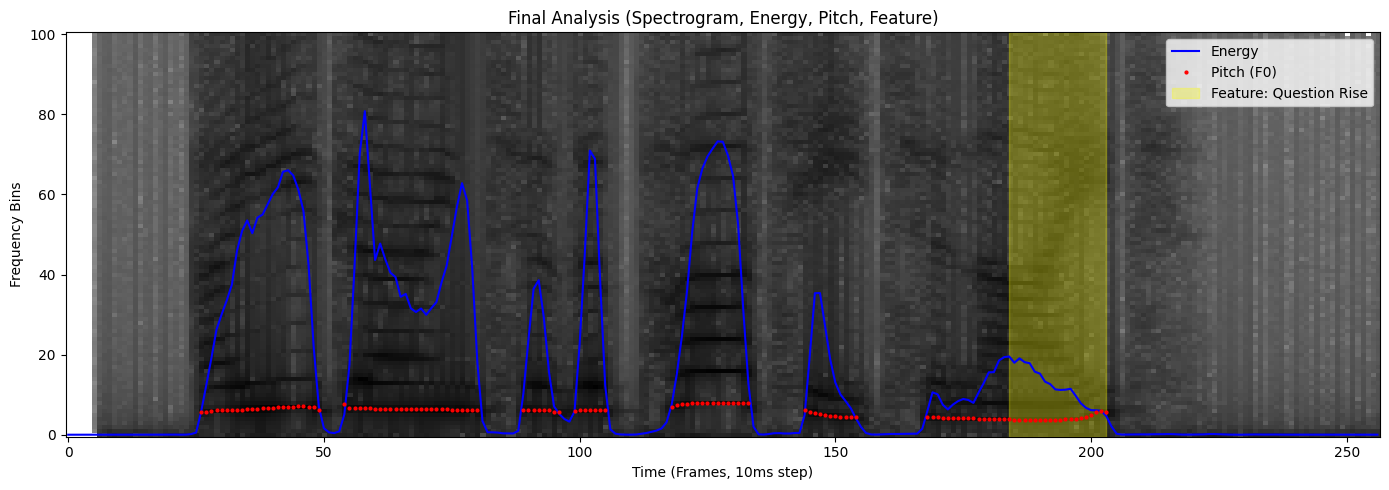

In [6]:

feature_detected = False
rise_start_frame = 0
rise_end_frame = 0

valid_pitch_indices = np.where(np.array(pitch_data_hz) > 0)[0]

if len(valid_pitch_indices) > 20:
    last_speech_indices = valid_pitch_indices[-20:]
    start_pitch = pitch_data_hz[last_speech_indices[0]]
    end_pitch = pitch_data_hz[last_speech_indices[-1]]

    if (end_pitch - start_pitch) > 30:
        feature_detected = True
        rise_start_frame = last_speech_indices[0]
        rise_end_frame = last_speech_indices[-1]
        print(f"👉 Feature detected! Possibly a question (pitch rises from {start_pitch:.1f}Hz to {end_pitch:.1f}Hz).")
    else:
        print("👉 No question rise detected (ending intonation is flat or falling).")
else:
    print("👉 Valid pitch segment in audio too short to determine.")

print("\n✅ Drawing final complete chart...")

plt.figure(figsize=(14, 5))
plt.imshow(spectrogram_matrix, aspect='auto', origin='lower', cmap='gray_r')
plt.plot(energy_normalized, color='blue', linewidth=1.5, label='Energy')
plt.plot(pitch_bins, color='red', marker='.', markersize=4, linestyle='none', label='Pitch (F0)')

if feature_detected:
    plt.axvspan(rise_start_frame, rise_end_frame, color='yellow', alpha=0.3, label='Feature: Question Rise')

plt.title("Final Analysis (Spectrogram, Energy, Pitch, Feature)")
plt.xlabel("Time (Frames, 10ms step)")
plt.ylabel("Frequency Bins")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()